In [1]:
# Step 1: Load the customer RFM table exported from BigQuery
import pandas as pd

df = pd.read_csv("customer_rfm.csv")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (5848, 14)


,customer_id,country,first_order_date,last_order_date,cohort_month,recency_days,frequency,monetary_gbp,r_score,f_score,m_score,rfm_code,segment,is_high_value
0,18102,United Kingdom,2009-12-01,2011-12-09,2009-12-01,0,145,579704.64,5,5,5,555,1. Champions,True
1,14646,Netherlands,2009-12-02,2011-12-08,2009-12-01,1,145,526751.52,5,5,5,555,1. Champions,True
2,14156,EIRE,2009-12-01,2011-11-30,2009-12-01,9,143,302029.92,5,5,5,555,1. Champions,True
3,14911,EIRE,2009-12-01,2011-12-08,2009-12-01,1,369,260405.88,5,5,5,555,1. Champions,True
4,17450,United Kingdom,2010-09-27,2011-12-01,2010-09-01,8,50,238459.17,5,5,5,555,1. Champions,True


In [3]:
# Step 2: Prepare the three RFM measures for clustering
import numpy as np
from sklearn.preprocessing import StandardScaler

features = df[["recency_days", "frequency", "monetary_gbp"]].astype(float)

# 1. How lopsided is the raw data? (near 0 = balanced; above 1 = a few huge values dominate)
print("Skew before log transform:")
print(features.skew().round(2))

# 2. Log transform: shrinks extreme values so a few huge customers don't dominate
features_log = np.log1p(features)
print("\nSkew after log transform:")
print(features_log.skew().round(2))

# 3. Standardize: puts all three measures on the same scale (average 0, spread 1)
scaler = StandardScaler()
X = scaler.fit_transform(features_log)
print("\nReady for clustering:", X.shape)

Skew before log transform:
recency_days     0.89
frequency       11.97
monetary_gbp    26.55
dtype: float64

Skew after log transform:
recency_days   -0.55
frequency       1.01
monetary_gbp    0.25
dtype: float64

Ready for clustering: (5848, 3)


 k  inertia  silhouette
 2   8559.0       0.439
 3   6335.0       0.348
 4   4930.0       0.364
 5   4111.0       0.341
 6   3564.0       0.336
 7   3187.0       0.304
 8   2898.0       0.307


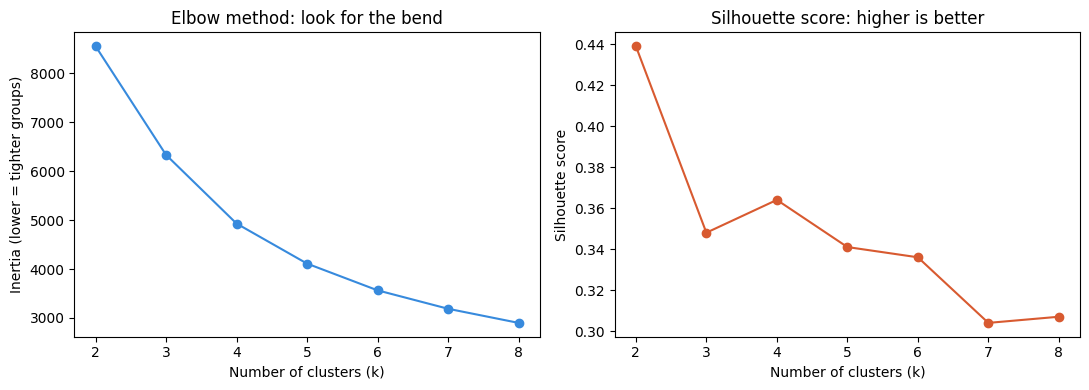

In [4]:
# Step 3: Test k = 2 to 8 clusters and compare them
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    results.append({
        "k": k,
        "inertia": round(km.inertia_, 0),
        "silhouette": round(silhouette_score(X, km.labels_), 3),
    })

results = pd.DataFrame(results)
print(results.to_string(index=False))

# Charts: elbow (left) and silhouette (right)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(results["k"], results["inertia"], marker="o", color="#378ADD")
ax1.set_title("Elbow method: look for the bend")
ax1.set_xlabel("Number of clusters (k)")
ax1.set_ylabel("Inertia (lower = tighter groups)")
ax2.plot(results["k"], results["silhouette"], marker="o", color="#D85A30")
ax2.set_title("Silhouette score: higher is better")
ax2.set_xlabel("Number of clusters (k)")
ax2.set_ylabel("Silhouette score")
plt.tight_layout()
plt.savefig("kmeans_choose_k.png", dpi=150)
plt.show()

In [5]:
# Step 4: Fit the final model with k = 4 and profile each cluster
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
df["cluster"] = kmeans.labels_

profile = (
    df.groupby("cluster")
      .agg(customers=("customer_id", "count"),
           median_days_since_last_order=("recency_days", "median"),
           median_orders=("frequency", "median"),
           median_spend_gbp=("monetary_gbp", "median"),
           total_sales_gbp=("monetary_gbp", "sum"))
)
profile["pct_customers"] = (100 * profile["customers"] / profile["customers"].sum()).round(1)
profile["pct_sales"] = (100 * profile["total_sales_gbp"] / profile["total_sales_gbp"].sum()).round(1)
profile = profile.sort_values("median_spend_gbp", ascending=False).round(0)

profile

,customers,median_days_since_last_order,median_orders,median_spend_gbp,total_sales_gbp,pct_customers,pct_sales
cluster,,,,,,,
2,1152,16.0,13.0,4978.0,12122048.0,20.0,73.0
3,1475,176.0,5.0,1484.0,2821511.0,25.0,17.0
0,1239,23.0,3.0,725.0,1047778.0,21.0,6.0
1,1982,400.0,1.0,274.0,629810.0,34.0,4.0


In [6]:
# Step 5: Name each cluster from its profile, then compare with the RFM segments
cluster_names = {
    2: "Core accounts",
    3: "Lapsing regulars",
    0: "Recent, still developing",
    1: "Lapsed one-timers",
}
df["cluster_name"] = df["cluster"].map(cluster_names)

# For each RFM segment (row), the % of its customers in each cluster (column). Rows add up to 100%.
comparison = pd.crosstab(df["segment"], df["cluster_name"], normalize="index").mul(100).round(0)
comparison = comparison[["Core accounts", "Lapsing regulars", "Recent, still developing", "Lapsed one-timers"]]
comparison

cluster_name,Core accounts,Lapsing regulars,"Recent, still developing",Lapsed one-timers
segment,,,,
1. Champions,75.0,8.0,17.0,0.0
2. Loyal,9.0,51.0,38.0,2.0
3. New / Promising,0.0,1.0,92.0,7.0
4. At Risk,2.0,85.0,0.0,13.0
5. Needs Attention,0.0,11.0,19.0,70.0
6. Hibernating,0.0,6.0,0.0,94.0


Loyal customers already drifting: 605
Their median days since last order: 98.0
Their median number of orders: 5.0
Their total lifetime sales: £1,215,280


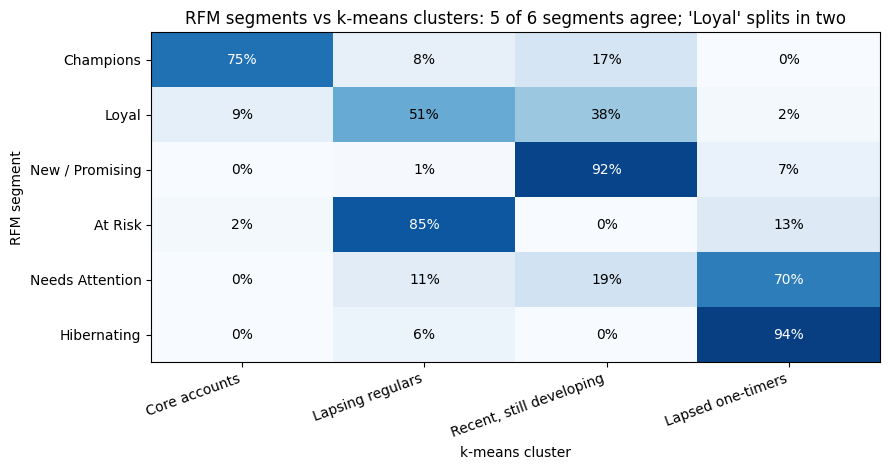

Saved: rfm_vs_kmeans.png, kmeans_choose_k.png, customer_clusters.csv


In [8]:
# Step 6a: How big is the early-warning group (Loyal customers already drifting)?
drifting = df[(df["segment"] == "2. Loyal") & (df["cluster_name"] == "Lapsing regulars")]
print("Loyal customers already drifting:", len(drifting))
print("Their median days since last order:", drifting["recency_days"].median())
print("Their median number of orders:", drifting["frequency"].median())
print("Their total lifetime sales: £{:,.0f}".format(drifting["monetary_gbp"].sum()))

# Step 6b: Chart comparing RFM segments with k-means clusters (saved for GitHub)
fig, ax = plt.subplots(figsize=(9, 4.8))
im = ax.imshow(comparison.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(comparison.columns)))
ax.set_xticklabels(comparison.columns, rotation=20, ha="right")
ax.set_yticks(range(len(comparison.index)))
ax.set_yticklabels([s.split(". ", 1)[1] for s in comparison.index])
for i in range(comparison.shape[0]):
    for j in range(comparison.shape[1]):
        v = comparison.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", color="white" if v > 55 else "black", fontsize=10)
ax.set_title("RFM segments vs k-means clusters: 5 of 6 segments agree; 'Loyal' splits in two")
ax.set_xlabel("k-means cluster")
ax.set_ylabel("RFM segment")
plt.tight_layout()
plt.savefig("rfm_vs_kmeans.png", dpi=150)
plt.show()

# Step 6c: Save each customer's segment and cluster (for GitHub)
df[["customer_id", "segment", "cluster_name", "recency_days", "frequency", "monetary_gbp"]].to_csv(
    "customer_clusters.csv", index=False)
print("Saved: rfm_vs_kmeans.png, kmeans_choose_k.png, customer_clusters.csv")